In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.core.viz.style import apply_style, ITALY_C, EU_C, PEER_C
apply_style()


# Hours versus pay: INPS private-sector employees in Forlì-Cesena (`2008–2025`)

A reader of post 01 noted that the MEF income per recipient (−1.68% real, 2008–2024) puts a twelve-month full-time job and a part-time or three-month contract on the same footing, and that part-time grew in Italy after 2008. The MEF tables show neither hours nor contracts. This notebook uses a second source to bound the order of magnitude.

**Data:** INPS *Osservatorio sui lavoratori dipendenti* (private non-agricultural employees), by **province of work**: workers with at least one paid day in the year, annual pay, paid days, and the cut by `Presenza tempo parziale nell'anno` (`Si` = at least one part-time relationship in the year, not only part-time). The part-time cut exists for `2008–2018`, `2024` and `2025` only (the `2019–2023` blocks, published by INPS on 2026-11-24, carry no `No`/`Si`), so the part-time comparison uses the endpoints 2024 and 2025 (2025 is classified ATECO 2025, irrelevant for province totals). Totals of workers, pay and paid days exist for every year `2008–2025`; the 2021 values are those revised on 2026-11-24 (section 6).

**Limits (stated before the results):**
- Paid days are not hours: horizontal part-time counts whole days, so days per worker understate any hours effect.
- The universe is not the MEF one: INPS is workplace, province, private non-agricultural employees; the MEF item is residence, municipality, and includes co.co.co., grants and replacement benefits.
- A worker with several jobs counts once, classified by the last job. Descriptive only, not causal.

In [2]:
from cifresignificative.core.sources import inps_osservatorio as inps
from cifresignificative.studies.cesena.analysis import hours as h

raw = inps.load()
panel = h.province_panel(raw)
print(f"rows {len(raw)}; years {sorted(raw.year.unique())}; provinces {raw[raw.kind == 'province'].province.nunique()}")
keep = h.comparable_provinces(panel, (2008, 2024))
keep_all = h.comparable_provinces(panel, (2008, 2024), strict=False)
print(f"comparable provinces 2008-2024: {len(keep)} (strict, territory unchanged), {len(keep_all)} (all present in both years); dropped as redrawn: {sorted(set(keep_all) - set(keep))}")

rows 4652; years [np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]; provinces 107
comparable provinces 2008-2024: 95 (strict, territory unchanged), 103 (all present in both years); dropped as redrawn: ['Ascoli Piceno', 'Bari', 'Cagliari', 'Foggia', 'Milano', 'Nuoro', 'Oristano', 'Sassari']


## 1. Forlì-Cesena: share of workers with part-time, paid days and pay per day

In [3]:
fc = panel.xs(h.UNIT, level="province")
oth = panel.drop(index=h.UNIT, level="province")
oth = oth[oth.index.get_level_values("province").isin(h.comparable_provinces(panel, (2008, 2024)))]
med = oth.groupby("year")[["share_pt_pct", "days_per_worker", "pay_per_day", "pt_pay_per_day_ratio"]].median()
tab = pd.DataFrame({
    "workers": fc.workers, "share_pt_pct": fc.share_pt_pct, "share_pt_median_others": med.share_pt_pct,
    "days_per_worker": fc.days_per_worker, "days_per_worker_median_others": med.days_per_worker,
    "days_pw_no": fc.days_per_worker_no, "days_pw_si": fc.days_per_worker_si,
    "pay_per_day_no": fc.pay_per_day_no, "pay_per_day_si": fc.pay_per_day_si, "pt_to_ft_pay_per_day": fc.pt_pay_per_day_ratio,
})
display(tab.round(2))

,workers,share_pt_pct,share_pt_median_others,days_per_worker,days_per_worker_median_others,days_pw_no,days_pw_si,pay_per_day_no,pay_per_day_si,pt_to_ft_pay_per_day
year,,,,,,,,,,
2008,114328.0,24.40,23.79,244.69,242.63,254.72,213.60,81.66,45.82,0.56
2009,112852.0,23.94,24.75,239.52,238.50,246.39,217.69,84.14,46.60,0.55
2010,113218.0,23.91,25.60,239.11,237.05,245.01,220.33,86.94,48.00,0.55
2011,114548.0,24.08,26.09,238.76,237.14,243.72,223.12,88.71,48.69,0.55
2012,111167.0,26.60,28.28,237.70,234.89,245.40,216.44,91.01,49.61,0.55
2013,106765.0,28.10,29.93,240.30,238.46,249.49,216.79,92.56,50.27,0.54
2014,104885.0,29.03,30.81,242.93,241.43,251.98,220.81,94.01,50.85,0.54
2015,106371.0,30.50,32.25,242.37,238.89,252.58,219.11,96.40,51.93,0.54
2016,108365.0,31.51,33.04,245.81,243.31,256.19,223.27,96.84,52.57,0.54


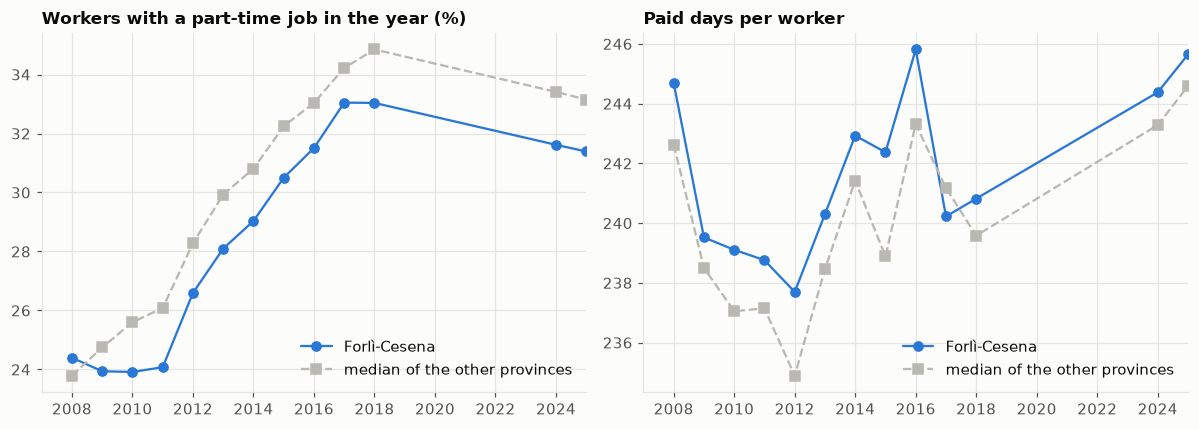

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(fc.index, fc.share_pt_pct, "o-", color=ITALY_C, label="Forlì-Cesena")
ax[0].plot(med.index, med.share_pt_pct, "s--", color=PEER_C, label="median of the other provinces")
ax[0].set_title("Workers with a part-time job in the year (%)"); ax[0].legend(); ax[0].set_xlim(2007, 2025)
ax[1].plot(fc.index, fc.days_per_worker, "o-", color=ITALY_C, label="Forlì-Cesena")
ax[1].plot(med.index, med.days_per_worker, "s--", color=PEER_C, label="median of the other provinces")
ax[1].set_title("Paid days per worker"); ax[1].legend(); ax[1].set_xlim(2007, 2025)
plt.tight_layout(); plt.show()

The line breaks between 2018 and 2024 are the years `2019–2023` without the part-time cut, not a series with a gap filled in.

## 2. Mean pay per worker: change of composition versus change within groups

Mean pay per worker `w = (1−s)·m_No + s·m_Si` (`s` = share of workers with part-time in the year). Between two years `within` is the change of `w` at constant share, `mix` is what the change of the share alone does (negative = drag), and `(1+within)(1+mix) = 1+total` exactly. All nominal and ratio-based, so no deflator is involved.

In [5]:
cols = ["share_pt_0", "share_pt_1", "share_pt_change_pp", "workers_change_pct", "days_per_worker_change_pct", "pay_per_day_change_pct", "pay_per_worker_change_pct", "within_pct", "mix_pct"]
out = {}
for y1 in (2024, 2018, 2025):
    dec = h.mix_decomposition(panel, 2008, y1, h.comparable_provinces(panel, (2008, y1)))
    out[y1] = dec
    print(f"\n--- 2008-{y1}: {len(dec)} provinces (territory unchanged) ---")
    display(pd.concat({"Forlì-Cesena": dec.loc[[h.UNIT], cols].iloc[0], "median others": dec.drop(index=h.UNIT)[cols].median()}, axis=1).round(2))
    display(h.unit_vs_others(dec)[["unit", "median_others", "rank", "n_others", "share_others_below_pct"]].round(2))


--- 2008-2024: 95 provinces (territory unchanged) ---


,Forlì-Cesena,median others
share_pt_0,24.40,23.79
share_pt_1,31.62,33.41
share_pt_change_pp,7.22,8.49
workers_change_pct,16.01,15.45
days_per_worker_change_pct,-0.13,0.75
pay_per_day_change_pct,26.92,21.42
pay_per_worker_change_pct,26.76,23.22
within_pct,32.34,31.35
mix_pct,-4.22,-5.12


,unit,median_others,rank,n_others,share_others_below_pct
share_pt_0,24.40,23.79,43.0,94.0,55.32
share_pt_1,31.62,33.41,59.0,94.0,38.30
share_pt_change_pp,7.22,8.49,56.0,94.0,41.49
workers_change_pct,16.01,15.45,46.0,94.0,52.13
days_per_worker_change_pct,-0.13,0.75,65.0,94.0,31.91
pay_per_day_change_pct,26.92,21.42,13.0,94.0,87.23
pay_per_worker_change_pct,26.76,23.22,20.0,94.0,79.79
within_pct,32.34,31.35,41.0,94.0,57.45
mix_pct,-4.22,-5.12,34.0,94.0,64.89
pt_pay_per_day_ratio_0,0.56,0.51,1.0,94.0,100.00



--- 2008-2018: 95 provinces (territory unchanged) ---


,Forlì-Cesena,median others
share_pt_0,24.40,23.79
share_pt_1,33.04,34.85
share_pt_change_pp,8.64,9.63
workers_change_pct,3.30,2.79
days_per_worker_change_pct,-1.58,-0.73
pay_per_day_change_pct,13.62,9.91
pay_per_worker_change_pct,11.83,8.55
within_pct,17.89,17.79
mix_pct,-5.14,-6.38


,unit,median_others,rank,n_others,share_others_below_pct
share_pt_0,24.40,23.79,43.0,94.0,55.32
share_pt_1,33.04,34.85,58.0,94.0,39.36
share_pt_change_pp,8.64,9.63,62.0,94.0,35.11
workers_change_pct,3.30,2.79,46.0,94.0,52.13
days_per_worker_change_pct,-1.58,-0.73,70.0,94.0,26.60
pay_per_day_change_pct,13.62,9.91,13.0,94.0,87.23
pay_per_worker_change_pct,11.83,8.55,25.0,94.0,74.47
within_pct,17.89,17.79,47.0,94.0,51.06
mix_pct,-5.14,-6.38,29.0,94.0,70.21
pt_pay_per_day_ratio_0,0.56,0.51,1.0,94.0,100.00



--- 2008-2025: 95 provinces (territory unchanged) ---


,Forlì-Cesena,median others
share_pt_0,24.40,23.79
share_pt_1,31.39,33.15
share_pt_change_pp,6.99,8.29
workers_change_pct,18.24,17.88
days_per_worker_change_pct,0.39,1.29
pay_per_day_change_pct,30.42,24.75
pay_per_worker_change_pct,30.93,26.50
within_pct,36.49,34.67
mix_pct,-4.08,-4.83


,unit,median_others,rank,n_others,share_others_below_pct
share_pt_0,24.40,23.79,43.0,94.0,55.32
share_pt_1,31.39,33.15,59.0,94.0,38.30
share_pt_change_pp,6.99,8.29,59.0,94.0,38.30
workers_change_pct,18.24,17.88,45.0,94.0,53.19
days_per_worker_change_pct,0.39,1.29,61.0,94.0,36.17
pay_per_day_change_pct,30.42,24.75,12.0,94.0,88.30
pay_per_worker_change_pct,30.93,26.50,19.0,94.0,80.85
within_pct,36.49,34.67,36.0,94.0,62.77
mix_pct,-4.08,-4.83,31.0,94.0,68.09
pt_pay_per_day_ratio_0,0.56,0.51,1.0,94.0,100.00


## 3. Placebo ranking: where Forlì-Cesena sits among all provinces, then among Emilia-Romagna

Emilia-Romagna provinces: ['Piacenza', 'Parma', 'Reggio Emilia', 'Modena', 'Bologna', 'Ferrara', 'Ravenna', 'Forlì-Cesena', 'Rimini']


,share_pt_change_pp,days_per_worker_change_pct,pay_per_day_change_pct,within_pct,mix_pct,pay_per_worker_change_pct
province,,,,,,
Piacenza,3.32,-1.63,24.11,24.50,-1.94,22.09
Parma,4.50,0.32,27.92,32.19,-2.91,28.34
Reggio Emilia,6.41,-0.91,25.14,29.06,-3.92,24.00
Modena,5.52,-0.07,27.94,32.60,-3.58,27.85
Bologna,5.95,-0.92,24.24,28.19,-3.98,23.09
Ferrara,8.69,-1.58,20.19,25.06,-5.42,18.29
Ravenna,7.38,1.13,25.51,32.91,-4.50,26.92
Forlì-Cesena,7.22,-0.13,26.92,32.34,-4.22,26.76
Rimini,6.35,0.74,24.54,30.81,-4.09,25.46


,unit,median_others,rank,n_others,share_others_below_pct
share_pt_change_pp,7.22,6.15,3.0,8.0,75.0
days_per_worker_change_pct,-0.13,-0.49,5.0,8.0,50.0
within_pct,32.34,29.93,3.0,8.0,75.0
mix_pct,-4.22,-3.95,7.0,8.0,25.0


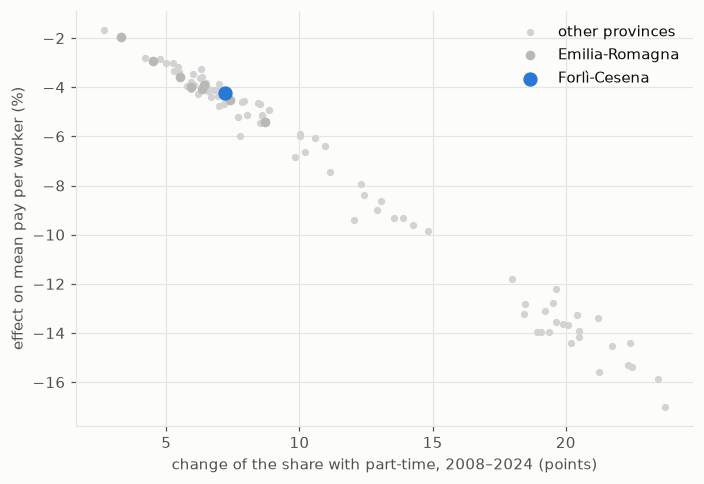

In [6]:
dec = out[2024]
er = [p for p in h.ER_PROVINCES if p in dec.index]
print("Emilia-Romagna provinces:", er)
display(dec.loc[er, ["share_pt_change_pp", "days_per_worker_change_pct", "pay_per_day_change_pct", "within_pct", "mix_pct", "pay_per_worker_change_pct"]].round(2))
display(h.unit_vs_others(dec, others=er)[["unit", "median_others", "rank", "n_others", "share_others_below_pct"]].round(2).loc[["share_pt_change_pp", "days_per_worker_change_pct", "within_pct", "mix_pct"]])

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(dec.share_pt_change_pp, dec.mix_pct, s=14, color="lightgray", label="other provinces")
ax.scatter(dec.loc[er].share_pt_change_pp, dec.loc[er].mix_pct, s=28, color=PEER_C, label="Emilia-Romagna")
ax.scatter(*dec.loc[h.UNIT, ["share_pt_change_pp", "mix_pct"]], s=70, color=ITALY_C, label=h.UNIT, zorder=3)
ax.set_xlabel("change of the share with part-time, 2008–2024 (points)"); ax.set_ylabel("effect on mean pay per worker (%)"); ax.legend()
plt.tight_layout(); plt.show()

## 4. Robustness

Endpoint 2018 or 2025 instead of 2024 (above), and the provinces whose territory changed (Milano and Monza, Ascoli Piceno and Fermo, Bari, Foggia and Barletta-Andria-Trani, the Sardinian provinces) kept in instead of dropped. Mean instead of median of the others.

In [7]:
rows = []
for y1 in (2024, 2018, 2025):
    for strict in (True, False):
        d_ = h.mix_decomposition(panel, 2008, y1, h.comparable_provinces(panel, (2008, y1), strict))
        o = d_.drop(index=h.UNIT)
        rows.append({"window": f"2008-{y1}", "territory unchanged only": strict, "n": len(d_),
                     "mix FC": d_.loc[h.UNIT, "mix_pct"], "mix median others": o.mix_pct.median(), "mix mean others": o.mix_pct.mean(),
                     "share change FC (pp)": d_.loc[h.UNIT, "share_pt_change_pp"], "share change median others": o.share_pt_change_pp.median()})
display(pd.DataFrame(rows).round(2))

,window,territory unchanged only,n,mix FC,mix median others,mix mean others,share change FC (pp),share change median others
0,2008-2024,True,95,-4.22,-5.12,-7.25,7.22,8.49
1,2008-2024,False,103,-4.22,-5.30,-7.37,7.22,8.58
2,2008-2018,True,95,-5.14,-6.38,-8.56,8.64,9.63
3,2008-2018,False,103,-5.14,-6.54,-8.76,8.64,10.17
4,2008-2025,True,95,-4.08,-4.83,-7.07,6.99,8.29
5,2008-2025,False,103,-4.08,-5.08,-7.19,6.99,8.37


## 5. Claims computed from the data

The figures quoted in the takeaways are computed in `analysis/claims.py` (`_hours`, run `uv run python -m cifresignificative.studies.cesena.analysis.claims` after changing the data) and shown below.

In [8]:
from cifresignificative.studies.cesena.analysis.claims import claims_for_notebook

display(claims_for_notebook("06"))

,id,text,window,source
0,hours_share_0824,+7.22 pp,2008-2024,data/raw/inps_osservatorio (INPS Osservatorio ...
1,hours_share_0824_rank,#56 of 95,2008-2024,data/raw/inps_osservatorio (INPS Osservatorio ...
2,hours_share_0824_others,+8.49 pp,2008-2024,data/raw/inps_osservatorio (INPS Osservatorio ...
3,hours_days_0824,-0.13%,2008-2024,data/raw/inps_osservatorio (INPS Osservatorio ...
4,hours_days_0824_rank,#65 of 95,2008-2024,data/raw/inps_osservatorio (INPS Osservatorio ...
...,...,...,...,...
242,hours_wt_share_2125_rank,#37 of 95,2021-2025,data/raw/inps_osservatorio (INPS Osservatorio ...
243,hours_wt_share_2125_others,-0.07 pp,2021-2025,data/raw/inps_osservatorio (INPS Osservatorio ...
244,hours_wt_level_2008,18.7%,2008,data/raw/inps_osservatorio (INPS Osservatorio ...
245,hours_wt_level_2019,26.9%,2019,data/raw/inps_osservatorio (INPS Osservatorio ...


## 6. Totals 2019–2025 (no part-time cut)

For `2019–2023` the Osservatorio gives only workers, pay and paid days by province (the part-time cut is missing), so it cannot extend sections 1–4; the totals are enough for the post-pandemic years. Growth is nominal; 2020 is the pandemic year. Provinces with a section hidden by the privacy threshold in the Open Data check (Arezzo, Matera) are dropped. The Open Data dataflow `DFB_ST_DIP_ATECO07_PROV_ANAG_01` agrees with the Osservatorio to the unit on 2014–2020 (except a masked cell) and is only a cross-check: for **2021 INPS revised the Osservatorio** on 2026-11-24 (Forlì-Cesena 122,340 workers, 122,085 in Open Data), and the Osservatorio is used.

In [9]:
tot = h.totals_panel(inps.load_totals())
display(tot.xs(h.UNIT, level="province").round(1))
rows = []
for y0, y1 in ((2019, 2020), (2019, 2021), (2021, 2022), (2022, 2023), (2023, 2024), (2024, 2025), (2021, 2025), (2019, 2025)):
    g = h.totals_growth(tot, y0, y1, h.comparable_provinces(tot, (y0, y1)))
    r = h.unit_vs_others(g)[["unit", "median_others", "rank", "n_others"]]
    rows.append(r.assign(window=f"{y0}-{y1}").reset_index(names="measure"))
display(pd.concat(rows).set_index(["window", "measure"]).round(2))

,workers,pay_eur,paid_days,days_per_worker,pay_per_worker,pay_per_day
year,,,,,,
2008,114328.0,2.070940e+09,27974884.0,244.7,18114.0,74.0
2009,112852.0,2.053512e+09,27030270.0,239.5,18196.5,76.0
2010,113218.0,2.121160e+09,27071261.0,239.1,18735.2,78.4
2011,114548.0,2.179823e+09,27349386.0,238.8,19029.8,79.7
2012,111167.0,2.139943e+09,26423934.0,237.7,19249.8,81.0
2013,106765.0,2.099622e+09,25655763.0,240.3,19665.8,81.8
2014,104885.0,2.105118e+09,25479598.0,242.9,20070.7,82.6
2015,106371.0,2.169129e+09,25781421.0,242.4,20392.1,84.1
2016,108365.0,2.241995e+09,26637620.0,245.8,20689.3,84.2


unit  median_others  rank  n_others
window    measure                                                         
2019-2020 workers_change_pct          -3.10          -1.54  77.0      94.0
          days_per_worker_change_pct  -6.05          -8.57   6.0      94.0
          pay_per_day_change_pct       1.61           2.05  64.0      94.0
          pay_per_worker_change_pct   -4.54          -6.81   7.0      94.0
2019-2021 workers_change_pct           1.69           1.93  58.0      94.0
          days_per_worker_change_pct  -1.38          -2.60  10.0      94.0
          pay_per_day_change_pct       2.79           2.73  42.0      94.0
          pay_per_worker_change_pct    1.37          -0.09  11.0      94.0
2021-2022 workers_change_pct           4.58           4.15  45.0      94.0
          days_per_worker_change_pct   1.65           3.60  89.0      94.0
          pay_per_day_change_pct       1.02           0.66  26.0      94.0
          pay_per_worker_change_pct    2.70           4.13  84.0      94.0
2022-2023 workers_change_pct           2.61           2.34  36.0      94.0
          days_per_worker_change_pct   0.47           0.66  68.0      94.0
          pay_per_day_change_pct       2.61           2.72  59.0      94.0
          pay_per_worker_change_pct    3.10           3.48  73.0      94.0
2023-2024 workers_change_pct           1.04           1.90  76.0      94.0
          days_per_worker_change_pct   0.52           0.13  16.0      94.0
          pay_per_day_change_pct       3.55           3.50  46.0      94.0
          pay_per_worker_change_pct    4.08           3.62  15.0      94.0
2024-2025 workers_change_pct           1.92           1.40  30.0      94.0
          days_per_worker_change_pct   0.52           0.49  44.0      94.0
          pay_per_day_change_pct       2.76           2.50  31.0      94.0
          pay_per_worker_change_pct    3.29           3.12  37.0      94.0
2021-2025 workers_change_pct          10.50           9.86  41.0      94.0
          days_per_worker_change_pct   3.19           4.71  73.0      94.0
          pay_per_day_change_pct      10.30           9.78  36.0      94.0
          pay_per_worker_change_pct   13.82          15.41  68.0      94.0
2019-2025 workers_change_pct          12.37          11.44  43.0      94.0
          days_per_worker_change_pct   1.77           2.03  53.0      94.0
          pay_per_day_change_pct      13.38          12.80  32.0      94.0
          pay_per_worker_change_pct   15.39          15.04  41.0      94.0

In 2020 Forlì-Cesena lost more workers than the median of the other provinces and fewer paid days per worker; from 2021 workers are above 2019 and keep growing in line with the others. Pay per worker grows less than the median of the others in 2021–2022 and more in 2023–2024. Descriptive: the source does not say whether days were lost to short-time work, closures or contract changes. Claims below are computed in `analysis/claims.py`.

## 7. Part-time by working-time type, 2008–2025 (monthly observatory, mean of the twelve months; one measure over the whole series)

The monthly Osservatorio gives, by province, the **number of workers present in the month** by working-time type (full time, horizontal, vertical and mixed part-time), but not pay or days. It covers the years without the annual part-time cut and, on the endpoints, can be checked against it. Files: `tipo_orario_media_<year>` (annual mean only, filter `Mese: Media`; from 2021 the site blocks the month-by-month table for statistical confidentiality; the 2019–2020 month-by-month tables, checked, have the same mean). Years loaded: 2008–2015 and 2017–2025; **2016 is missing** (the INPS page is in error), shown as a gap in the figure. The column order differs between exports (type first or province first): the parser reads it from the header. **This is not the annual `Si/No` of sections 1–4:** a worker counts once for each month present, so the mean is below the annual count (Forlì-Cesena 2019: 99,717 against 120,305), and the share is the share of the stock in a month, not of anyone with a part-time relationship in the year. Levels of the two shares must not be compared; the changes can be read on their own. The four types add up to the total within 2 workers (rounding of the monthly means).

Forlì-Cesena                                           \
     workers_month part_time_share_pct share_horizontal_pct   
year                                                          
2008       95651.0               18.71                16.42   
2009       93980.0               19.26                16.85   
2010       94143.0               19.71                17.18   
2011       95141.0               20.12                17.58   
2012       92848.0               21.41                18.59   
2013       89561.0               23.19                20.01   
2014       87974.0               24.25                20.95   
2015       88456.0               25.38                21.83   
2017       95118.0               27.00                23.06   
2018       98213.0               26.86                23.17   
2019       99717.0               26.86                23.44   
2020       95179.0               25.83                22.48   
2021      101042.0               25.61                22.57   
2022      106097.0               25.47                22.47   
2023      109405.0               25.45                22.49   
2024      111307.0               25.56                22.52   
2025      113647.0               25.72                22.51   

                                              median others  \
     share_vertical_pct share_mixed_pct part_time_share_pct   
year                                                          
2008               0.76            1.53               19.48   
2009               0.74            1.66               20.51   
2010               0.78            1.75               21.53   
2011               0.77            1.77               22.46   
2012               0.94            1.88               23.82   
2013               1.07            2.11               25.96   
2014               1.10            2.21               27.23   
2015               1.08            2.47               27.65   
2017               1.23            2.71               29.14   
2018               1.17            2.52               29.76   
2019               1.05            2.38               30.10   
2020               1.01            2.34               28.59   
2021               0.89            2.15               28.36   
2022               0.90            2.10               28.70   
2023               0.84            2.12               28.49   
2024               0.87            2.17               28.66   
2025               0.90            2.31               28.53   

                                                              
     share_horizontal_pct share_vertical_pct share_mixed_pct  
year                                                          
2008                17.95               0.75            0.75  
2009                18.68               0.84            0.89  
2010                19.43               0.90            1.04  
2011                20.12               0.95            1.12  
2012                21.30               1.05            1.28  
2013                23.04               1.20            1.46  
2014                24.09               1.24            1.57  
2015                24.53               1.25            1.73  
2017                26.09               1.28            2.02  
2018                26.36               1.27            2.10  
2019                26.62               1.24            2.14  
2020                25.52               1.16            2.10  
2021                25.14               1.11            2.08  
2022                25.52               1.09            2.10  
2023                25.43               1.08            2.13  
2024                25.38               1.12            2.16  
2025                25.20               1.10            2.15

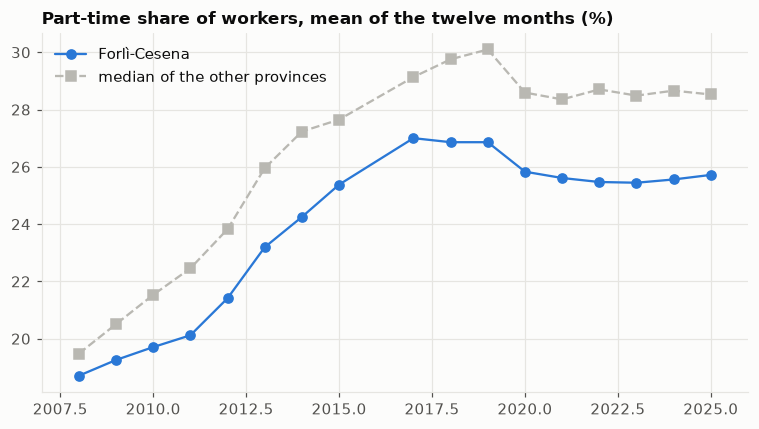

unit  median_others  rank  n_others
window    measure                                                       
2008-2025 share_change_pp            7.01           7.82  55.0      94.0
          workers_month_change_pct  18.81          19.52  49.0      94.0
2008-2019 share_change_pp            8.15           9.43  59.0      94.0
          workers_month_change_pct   4.25           3.74  46.0      94.0
2019-2025 share_change_pp           -1.14          -1.52  34.0      94.0
          workers_month_change_pct  13.97          12.59  41.0      94.0
2021-2025 share_change_pp            0.11          -0.07  37.0      94.0
          workers_month_change_pct  12.48          12.68  49.0      94.0

In [10]:
wt = inps.load_working_time()
wtp = h.working_time_panel(wt)
fcw = wtp.xs(h.UNIT, level="province")
medw = wtp.drop(index=h.UNIT, level="province").groupby("year")[["part_time_share_pct", "share_horizontal_pct", "share_vertical_pct", "share_mixed_pct"]].median()
display(pd.concat({"Forlì-Cesena": fcw[["workers_month", "part_time_share_pct", "share_horizontal_pct", "share_vertical_pct", "share_mixed_pct"]], "median others": medw}, axis=1).round(2))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(fcw.index, fcw.part_time_share_pct, "o-", color=ITALY_C, label="Forlì-Cesena")
ax.plot(medw.index, medw.part_time_share_pct, "s--", color=PEER_C, label="median of the other provinces")
ax.set_title("Part-time share of workers, mean of the twelve months (%)"); ax.legend(); ax.set_xlim(2007, 2026)
plt.tight_layout(); plt.show()
rows = []
for y0, y1 in ((2008, 2025), (2008, 2019), (2019, 2025), (2021, 2025)):
    r = h.unit_vs_others(h.working_time_change(wtp, y0, y1, h.comparable_provinces(wtp, (y0, y1))))[["unit", "median_others", "rank", "n_others"]]
    rows.append(r.assign(window=f"{y0}-{y1}").reset_index(names="measure"))
display(pd.concat(rows).set_index(["window", "measure"]).round(2))

Over the whole series the monthly part-time share of Forlì-Cesena rises from 18.7% in 2008 to 25.7% in 2025, +7.01 points against +7.82 for the median of the other provinces (#55 of 95), almost the same as the annual `Si` share of sections 1–2 (+6.99 points, 2008–2025): two different measures agree on the change. The path has two phases and no step: the share rises every year from 2008 to about 27% in 2017–2019 (the median of the others to about 30%), then it is flat or slightly lower: 26.9% in 2019, 25.7% in 2025, a fall of 1.14 points, a fall of 1.14 points against −1.52 for the median of the other provinces (#34 of 95); the fall is common, the province is in the middle. The rise before 2019 is gradual in both lines (2016 is missing, so the 2015–2017 step of about 1.6 points in Forlì-Cesena spans two years). It does not contradict the rise of the annual share between 2008 and 2025 (sections 1–2): the two shares measure different things and cover different years. Descriptive; horizontal part-time is about nine tenths of part-time in every year.

## 8. Real pay: composition and the two groups (2008–2024 and 2008–2018)

Sections 1–4 are nominal. Here pay is deflated with the national price index used in post 01 (`reports/income_evidence/deflator_audit.csv`, column `panel_chained_2020_1`), the same for every province, so ranks do not change; only the levels of the changes move. `within_real` is the mean at the 2008 part-time share; `(1+within_real)(1+mix) = 1+total_real`. The index stops at 2024, so 2025 is not deflated.

In [11]:
prices = pd.read_csv("studies/cesena/reports/income_evidence/deflator_audit.csv").set_index("year").panel_chained_2020_1
for y1 in (2024, 2018):
    rr = h.real_pay_changes(panel, 2008, y1, prices, h.comparable_provinces(panel, (2008, y1)))
    er = [p for p in h.ER_PROVINCES if p in rr.index]
    print(f"\n--- 2008-{y1}, real, {len(rr)} provinces ---")
    display(pd.concat({"all provinces": h.unit_vs_others(rr)[["unit", "median_others", "rank", "n_others"]],
                       "Emilia-Romagna": h.unit_vs_others(rr, others=er)[["median_others", "rank"]]}, axis=1).round(2))


--- 2008-2024, real, 95 provinces ---


all provinces                               \
                                       unit median_others  rank n_others   
pay_per_worker_real_pct               -6.02         -8.64  20.0     94.0   
within_real_pct                       -1.88         -2.61  41.0     94.0   
mix_pct                               -4.22         -5.12  34.0     94.0   
pay_per_worker_no_real_pct            -2.38         -3.14  40.0     94.0   
pay_per_worker_si_real_pct             1.44          1.83  53.0     94.0   
days_per_worker_no_change_pct         -0.24          0.59  61.0     94.0   

                              Emilia-Romagna       
                               median_others rank  
pay_per_worker_real_pct                -7.52  4.0  
within_real_pct                        -3.66  3.0  
mix_pct                                -3.95  7.0  
pay_per_worker_no_real_pct             -4.69  4.0  
pay_per_worker_si_real_pct             -0.34  4.0  
days_per_worker_no_change_pct          -0.55  4.0


--- 2008-2018, real, 95 provinces ---


all provinces                               \
                                       unit median_others  rank n_others   
pay_per_worker_real_pct               -1.18         -4.07  25.0     94.0   
within_real_pct                        4.17          4.09  47.0     94.0   
mix_pct                               -5.14         -6.38  29.0     94.0   
pay_per_worker_no_real_pct             3.88          4.04  51.0     94.0   
pay_per_worker_si_real_pct             6.07          4.94  36.0     94.0   
days_per_worker_no_change_pct         -1.52          0.07  82.0     94.0   

                              Emilia-Romagna       
                               median_others rank  
pay_per_worker_real_pct                -1.59  5.0  
within_real_pct                         3.81  5.0  
mix_pct                                -5.11  5.0  
pay_per_worker_no_real_pct              3.73  5.0  
pay_per_worker_si_real_pct              3.79  2.0  
days_per_worker_no_change_pct           0.08  7.0

From 2008 to 2024 real mean pay per worker in Forlì-Cesena changes −6.02% (median of the other provinces −8.64%, #20 of 95). At the 2008 part-time share it would be −1.88% (others −2.61%): most of the INPS fall is composition. Workers with no part-time relationship in the year, whose paid days barely move (254.7 and 254.1), still lose −2.38% (others −3.14%, #40 of 95), so the fall is not only hours. The loss is all after 2018: from 2008 to 2018 the same group gains +3.88% (others +4.04%). Descriptive; national prices, provinces of work, private employees.

## Takeaways

*Descriptive, not causal; INPS private non-agricultural employees by province of work, 2008, 2024 and 2025 for the part-time cut; nominal except item 6; 2019–2023 only as totals (the cut is missing there); 2021 as revised by INPS on 2026-11-24.*

1. **Part-time grew in Forlì-Cesena, as elsewhere.** The share of workers with at least one part-time relationship in the year goes from 24.4% to 31.6% (+7.22 points), against +8.49 points for the median of the other provinces (#56 of 95): the province is not an outlier.
2. **Paid days per worker barely moved:** 244.7 in 2008, 244.4 in 2024 (−0.13%; median of the others +0.75%). Days understate the effect of part-time, because a part-time day is paid much less than a full-time day: pay per paid day of workers with a part-time job is about 56% of the others, in both years.
3. **Composition lowers the mean.** At the pay of each group in 2024, the rise of the part-time share alone puts the mean pay per worker about 4.22% below what the 2008 share would give (median of the other provinces −5.12%; median of the other Emilia-Romagna provinces −3.95%, Forlì-Cesena #7 of 9). The rest, `within`, is +32.34% (nominal), against +31.35%.
4. **Reading for post 01:** a composition effect of about four percent in this source is of the same order of magnitude as the −1.68% real fall of MEF employment income per recipient, so the reader's mechanism is plausible and not negligible. It is not an attribution: the two universes differ (workplace versus residence, private employees versus MEF's broader item with co.co.co., grants and benefits), part-time here means at least one part-time relationship in the year, and days are not hours. Forlì-Cesena looks like the other provinces on every measure of this notebook.
5. **Robustness:** with the 2018 endpoint the composition effect is −5.14% (others −6.38%); with the 2025 endpoint it is −4.08% (others −4.83%; share +6.99 points against +8.29, #59 of 95); keeping the provinces with changed territory the median of the others is −5.30%; the picture does not change.
6. **Real pay (section 8, national price index of post 01):** from 2008 to 2024 the real mean pay per worker changes −6.02% (others −8.64%); at the 2008 part-time share −1.88% (others −2.61%); workers with no part-time in the year −2.38% (others −3.14%, #40 of 95), with the same paid days. Composition is the larger part of the INPS fall, but a real fall remains without it, and it comes after 2018 (2008–2018: +3.88% for the same group).
7. **Totals 2019–2025:** in 2020 Forlì-Cesena loses 3.10% of workers (median of the others −1.54%) and 6.05% of paid days per worker (others −8.57%, #6 of 95); in 2021, against 2019, workers are +1.69% and paid days per worker −1.38% (others −2.60%), pay per worker +1.37% nominal (others −0.09%, #11 of 95). From 2021 to 2025 workers are +10.50% (others +9.86%), paid days per worker +3.19% (others +4.71%, #73 of 95), pay per paid day +10.30% (others +9.78%) and pay per worker +13.82% (others +15.41%, #68 of 95). The 2021–2024 jump is no longer a gap: 2022 is +2.70% on pay per worker (others +4.13%), 2023 +3.10% (others +3.48%), 2024 +4.08% (others +3.62%). Forlì-Cesena stays near the middle of the provinces.

**Limits.** Paid days are not hours; a worker with several jobs counts once; the INPS cut `Si` includes full-time workers with a part-time job in the year; the part-time cut is missing for 2019–2023; the 2025 data use ATECO 2025 (no effect on province totals, a break for any sector cut); the 2021 Open Data copy differs from the revised Osservatorio. The conclusion for readers is bounded: part-time plausibly weighs several percent on mean annual pay per worker; it does not say how much of the −1.68% it accounts for.